### 1. Load Data & Initial Inspection
Load the Telco churn dataset and check basic shape, column types, and structure.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel('../Dataset/Telco_customer_churn.xlsx')
print(df.shape)
df.info()

(7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 

### 2. Missing Value Check
Check for nulls across all columns before doing any cleaning.

In [2]:
df.isnull().sum().sort_values(ascending=False)

Churn Reason         5174
CustomerID              0
Count                   0
State                   0
Country                 0
Zip Code                0
Lat Long                0
Latitude                0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Longitude               0
Internet Service        0
Online Security         0
Device Protection       0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Contract                0
Tech Support            0
Paperless Billing       0
Payment Method          0
Total Charges           0
Monthly Charges         0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

#### Observation
`Churn Reason` has 5,174 nulls — this is expected, since only churned customers 
(1,869 of them) have a reason logged. Non-churned customers naturally have no reason.

### 3. Investigating `Total Charges`
`Total Charges` is loaded as an object/string type instead of numeric. 
Let's find out why before blindly converting it.

In [3]:
df['Total Charges'].apply(type).value_counts()

Total Charges
<class 'float'>    6708
<class 'int'>       324
<class 'str'>        11
Name: count, dtype: int64

### 4. Converting `Total Charges` to Numeric
Attempt numeric conversion and flag any rows that fail — don't silently coerce and move on.

In [4]:
pd.to_numeric(df['Total Charges'], errors='coerce').isnull().sum()

np.int64(11)

### 5. Inspecting the Problem Rows
Let's look at the actual rows where `Total Charges` couldn't be converted to a number.

In [5]:
bad_rows = df[pd.to_numeric(df['Total Charges'], errors='coerce').isnull()]
bad_rows[['CustomerID', 'Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Label']]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


### 6. Fixing `Total Charges`
Rows with `Tenure Months = 0` have blank `Total Charges` because these are brand-new 
customers who haven't completed a billing cycle yet. Logically, their total charges 
should be 0, not missing. We'll convert the column to numeric and fill these with 0.

In [6]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

# Verify the fix
print(df['Total Charges'].dtype)
print(df['Total Charges'].isnull().sum())
df.loc[df['Tenure Months'] == 0, ['CustomerID', 'Tenure Months', 'Total Charges']]

float64
0


,CustomerID,Tenure Months,Total Charges
2234,4472-LVYGI,0,0.0
2438,3115-CZMZD,0,0.0
2568,5709-LVOEQ,0,0.0
2667,4367-NUYAO,0,0.0
2856,1371-DWPAZ,0,0.0
4331,7644-OMVMY,0,0.0
4687,3213-VVOLG,0,0.0
5104,2520-SGTTA,0,0.0
5719,2923-ARZLG,0,0.0
6772,4075-WKNIU,0,0.0


### 7. Dropping Irrelevant & Leakage-Prone Columns
Some columns add no analytical value (IDs, constants, redundant geo fields), 
and some are risky to keep because they were likely derived from the churn outcome 
itself (Churn Score, CLTV) — using them would be data leakage if we later build a model.

In [7]:
cols_to_drop = [
    'Count',           # always 1, no variance
    'Country',         # always 'United States'
    'Lat Long',        # redundant with Latitude/Longitude
]

df_clean = df.drop(columns=cols_to_drop)
df_clean.shape

(7043, 30)

### 8. Overall Churn Rate
Calculate the company's baseline churn rate — the single most important number in this project.

In [8]:
churn_rate = df_clean['Churn Value'].mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")

df_clean['Churn Label'].value_counts(normalize=True) * 100

Overall churn rate: 26.54%


Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

### 9. Churn Rate by Contract Type
Contract type is typically the strongest predictor of churn — let's verify that here.

In [9]:
contract_churn = df_clean.groupby('Contract')['Churn Value'].mean() * 100
contract_churn = contract_churn.sort_values(ascending=False)
print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn Value, dtype: float64


### 10. Visualizing Churn by Contract Type

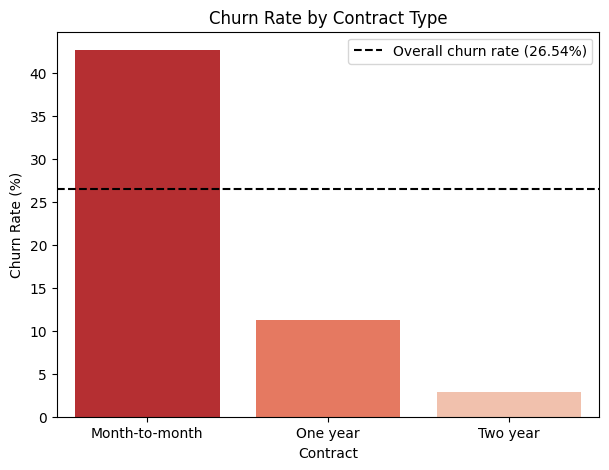

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))
sns.barplot(x=contract_churn.index, y=contract_churn.values,hue=contract_churn.index, palette='Reds_r')
plt.axhline(26.54, color='black', linestyle='--', label='Overall churn rate (26.54%)')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Contract Type')
plt.legend()
plt.show()

### 11. Churn Rate by Tenure
Check whether newer customers are more likely to churn than long-tenured ones.

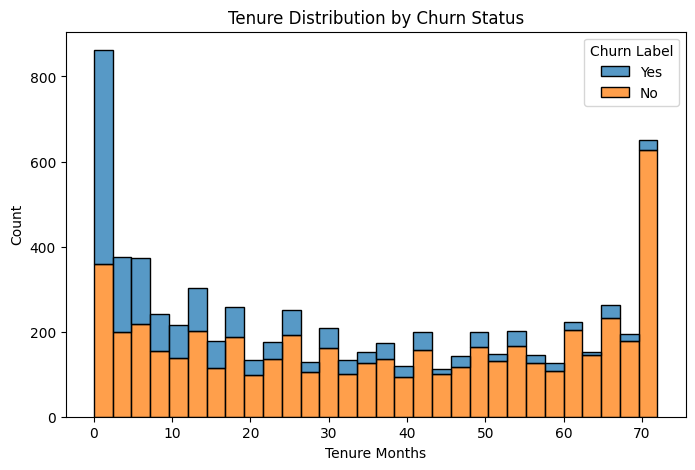

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(data=df_clean, x='Tenure Months', hue='Churn Label', multiple='stack', bins=30)
plt.title('Tenure Distribution by Churn Status')
plt.show()

### Observation
Churn is heavily concentrated among new customers. The 0–2 month tenure bin has both 
the highest customer count and the highest proportion of churned customers, with over 
40% of that bin leaving. In contrast, customers with 60+ months of tenure churn very 
rarely — the final bin is almost entirely retained customers. This suggests churn risk 
is highest during the early customer lifecycle (likely onboarding-related), and drops 
sharply the longer a customer stays. Combined with the Contract Type finding, this points 
to a "critical window" in the first few months where retention efforts would have the 
highest impact.

### 12. Tenure vs Contract Type
Check whether new customers are disproportionately on month-to-month contracts — 
if so, tenure and contract type may be capturing overlapping risk rather than 
two independent drivers.

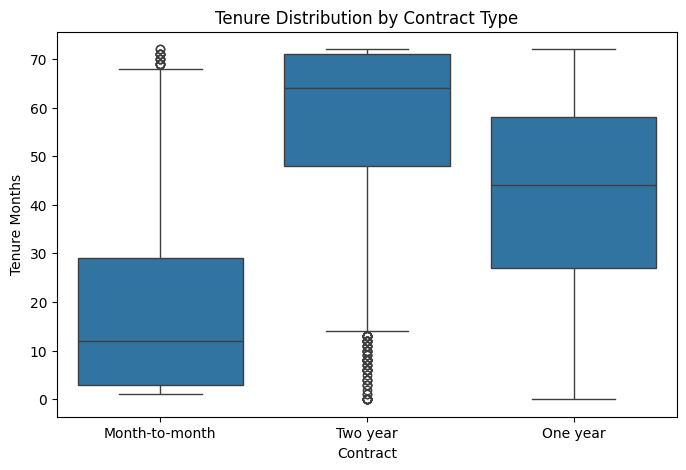

In [12]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, x='Contract', y='Tenure Months')
plt.title('Tenure Distribution by Contract Type')
plt.show()

### Observation
Month-to-month customers have a much lower median tenure (~12 months) 
compared to One year (~44 months) and Two year (~64 months) customers. This 
means month-to-month customers tend to be newer customers overall.

This confirms that tenure and contract type are correlated — 
short-tenure customers disproportionately choose month-to-month 
plans, which is consistent with our earlier finding that month-to-month customers 
churn at 42.71% compared to only 2.83% for two-year contracts.

The small cluster of low-tenure outliers within "Two year" contracts likely 
represents customers who recently signed a long-term contract, since tenure 
measures total time as a customer, not time remaining on the current contract.

### 13. Churn Rate by Internet Service Type
Check whether the type of internet service (Fiber optic, DSL, or none) 
is associated with different churn rates.

In [13]:
internet_service_churn = df_clean.groupby('Internet Service')['Churn Value'].mean() * 100
internet_service_churn = internet_service_churn.sort_values(ascending=False)
print(internet_service_churn)

Internet Service
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn Value, dtype: float64


### Observation
Fiber optic customers churn at 41.89%, nearly double the overall baseline 
of 26.54%, and notably higher than DSL (18.96%) or customers with no internet 
service (7.40%). This is counterintuitive since Fiber optic is typically the 
premium internet option — one would expect lower churn from a 
better service, not higher.

Possible explanations to investigate further: price sensitivity, service 
reliability issues, or competitor pressure in the fiber market.

### 14. Fiber Optic Churn Reasons

In [14]:
fiber_reasons = df_clean[df_clean['Internet Service'] == 'Fiber optic']['Churn Reason'].value_counts()
print(fiber_reasons)

Churn Reason
Attitude of support person                   133
Competitor offered higher download speeds    130
Competitor offered more data                 120
Competitor made better offer                 104
Attitude of service provider                 101
Don't know                                    97
Competitor had better devices                 82
Price too high                                71
Network reliability                           67
Product dissatisfaction                       66
Service dissatisfaction                       64
Lack of self-service on Website               62
Extra data charges                            43
Moved                                         40
Long distance charges                         33
Limited range of services                     27
Lack of affordable download/upload speed      27
Poor expertise of phone support               13
Poor expertise of online support              13
Deceased                                       4
Name: c

### Observation
Grouping the churn reasons into categories shows competitor pressure is the 
top driver (436 customers — better speeds, data, offers, or devices), followed 
by support/service attitude issues (322 customers). Price-related reasons (147) 
are actually smaller than expected — well behind both competitors and service 
attitude. This suggests churn is driven more by competitive positioning and 
customer service quality than by price alone.

### 15. Churn Rate by Payment Method

Payment Method
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn Value, dtype: float64


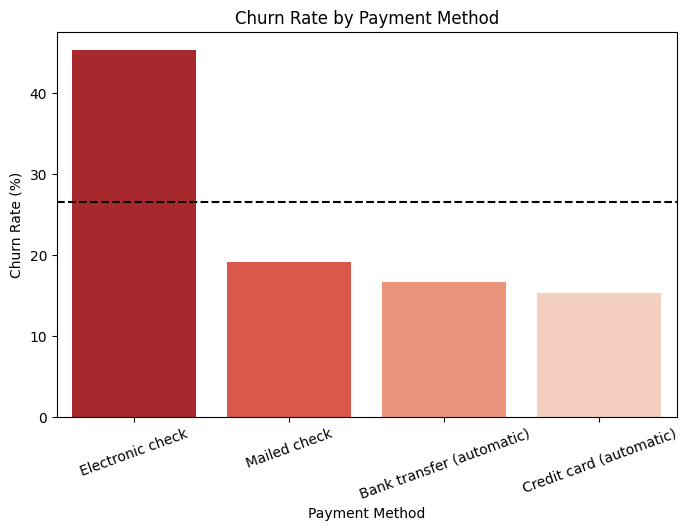

In [15]:
payment_churn = df_clean.groupby('Payment Method')['Churn Value'].mean().sort_values(ascending=False) * 100
print(payment_churn)

plt.figure(figsize=(8,5))
sns.barplot(x=payment_churn.index, y=payment_churn.values, hue=payment_churn.index, palette='Reds_r')
plt.axhline(26.54, color='black', linestyle='--', label='Overall churn rate (26.54%)')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Payment Method')
plt.xticks(rotation=20)
plt.show()

### Observation
Payment method shows a clear split: Electronic check has by far the highest churn 
(45.29%, well above the 26.54% baseline), while automatic payment methods (bank 
transfer, credit card) churn the least (~15-17%). This suggests customers on manual 
payment methods are more disengaged or price-sensitive, while automatic payments 
create stickiness — once billing is automated, customers are less likely to actively 
decide to leave.

### 16. Churn Rate by Add-on Services

In [16]:
addon_cols = ['Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies']

for col in addon_cols:
    print(f"\n--- {col} ---")
    print(df_clean.groupby(col)['Churn Value'].mean() * 100)


--- Online Security ---
Online Security
No                     41.766724
No internet service     7.404980
Yes                    14.611194
Name: Churn Value, dtype: float64

--- Online Backup ---
Online Backup
No                     39.928756
No internet service     7.404980
Yes                    21.531494
Name: Churn Value, dtype: float64

--- Device Protection ---
Device Protection
No                     39.127625
No internet service     7.404980
Yes                    22.502064
Name: Churn Value, dtype: float64

--- Tech Support ---
Tech Support
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: Churn Value, dtype: float64

--- Streaming TV ---
Streaming TV
No                     33.523132
No internet service     7.404980
Yes                    30.070188
Name: Churn Value, dtype: float64

--- Streaming Movies ---
Streaming Movies
No                     33.680431
No internet service     7.404980
Yes                    29.941435


### Observation
Add-on services (Online Security, Online Backup, Device Protection, Tech Support) 
show a strong pattern: customers WITHOUT these services churn 2-3x more than 
customers WITH them (e.g. Online Security: 41.77% without vs 14.61% with). 
Streaming TV/Movies are the exception — churn is similar whether customers have 
them or not (~30-34%), suggesting these are entertainment add-ons that don't 
build the same loyalty as security/support services. Overall, protective/support 
services appear to reduce churn, while streaming add-ons don't.

### 17. Churn Rate by Demographics

In [17]:
demo_cols = ['Gender', 'Senior Citizen', 'Partner', 'Dependents']

for col in demo_cols:
    print(f"\n--- {col} ---")
    print(df_clean.groupby(col)['Churn Value'].mean() * 100)


--- Gender ---
Gender
Female    26.920872
Male      26.160338
Name: Churn Value, dtype: float64

--- Senior Citizen ---
Senior Citizen
No     23.606168
Yes    41.681261
Name: Churn Value, dtype: float64

--- Partner ---
Partner
No     32.957979
Yes    19.664903
Name: Churn Value, dtype: float64

--- Dependents ---
Dependents
No     32.551699
Yes     6.515058
Name: Churn Value, dtype: float64


### Observation
Demographics show mixed signal strength. Gender has almost no effect on churn 
(Female 26.9% vs Male 26.2% — essentially the same). Senior Citizens churn 
notably more (41.68% vs 23.61%). The strongest demographic drivers are Partner 
and Dependents: customers without a partner (32.96% vs 19.66%) or without 
dependents (32.55% vs 6.52%) churn far more. This suggests customers with family 
ties at home are significantly more stable/loyal, possibly due to bundled 
household services or less willingness to disrupt shared accounts.

### 18. Monthly Charges Distribution vs Churn

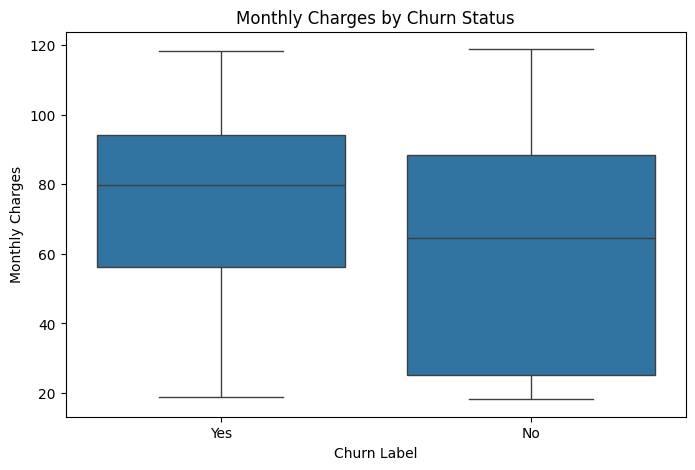

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, x='Churn Label', y='Monthly Charges')
plt.title('Monthly Charges by Churn Status')
plt.show()

### Observation
Churned customers pay noticeably higher Monthly Charges on median (~$80) compared 
to retained customers (~$65). This aligns with the earlier Fiber optic finding — 
Fiber optic is the pricier internet option and also had the highest churn rate 
(41.89%). Higher bills appear to increase churn risk, supporting price/value 
sensitivity as a real factor, even though "Price too high" wasn't the top stated 
reason for leaving.

### 19. Churn Reason — Overall

Churn Reason
Attitude of support person                   192
Competitor offered higher download speeds    189
Competitor offered more data                 162
Don't know                                   154
Competitor made better offer                 140
Attitude of service provider                 135
Competitor had better devices                130
Network reliability                          103
Product dissatisfaction                      102
Price too high                                98
Service dissatisfaction                       89
Lack of self-service on Website               88
Extra data charges                            57
Moved                                         53
Limited range of services                     44
Lack of affordable download/upload speed      44
Long distance charges                         44
Poor expertise of phone support               20
Poor expertise of online support              19
Deceased                                       6
Name: c

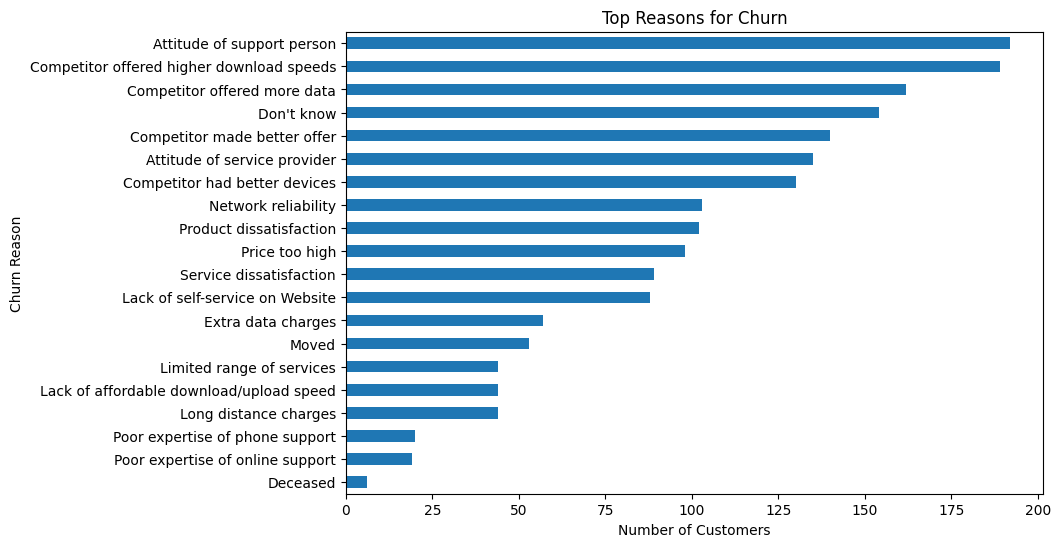

In [19]:
churn_reason_counts = df_clean['Churn Reason'].value_counts()
print(churn_reason_counts)

plt.figure(figsize=(9,6))
churn_reason_counts.plot(kind='barh')
plt.xlabel('Number of Customers')
plt.title('Top Reasons for Churn')
plt.gca().invert_yaxis()
plt.show()

### Observation

- **Support issues and competitive pressure** are the leading reasons for churn.
- **Poor support attitude** is the most frequently reported reason.
- Competitor **higher speeds, more data, and better offers** are also major contributors.
- This highlights the need to improve **service quality and competitive offerings**.

### 20. Correlation Heatmap (Numeric Features)

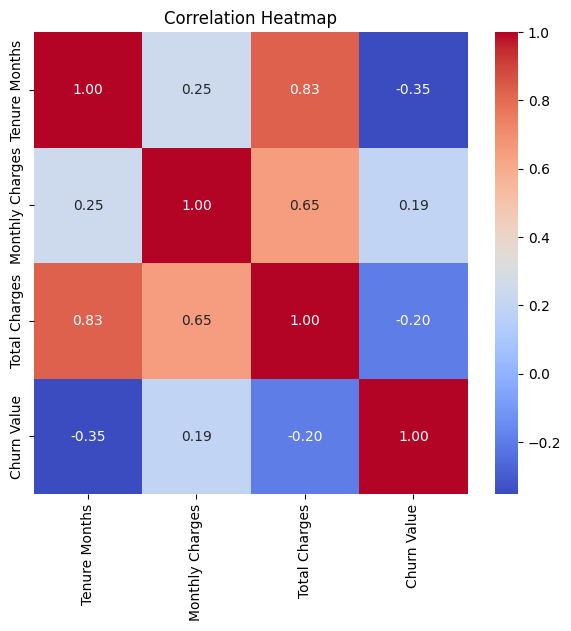

In [20]:
numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Value']

plt.figure(figsize=(7,6))
sns.heatmap(df_clean[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### Observation
Tenure has the strongest correlation with churn among numeric features (-0.35) — 
longer-tenured customers churn less, consistent with the earlier tenure histogram. 
Monthly Charges shows a weaker positive correlation (+0.19), meaning higher bills 
are mildly associated with more churn. Total Charges (-0.20) is influenced by its 
strong link to tenure (0.83) rather than being an independent driver. Overall, no 
single numeric variable is a very strong predictor alone — churn is better explained 
by categorical factors like Contract type and Internet Service, which we found have 
much bigger swings (e.g. 2.83% to 42.71% across contract types).

## 21. Summary — Top Churn Drivers from EDA

Based on the EDA above, the strongest churn drivers identified are:

1. **Payment Method** — Electronic check users churn at 45.29% vs 26.54% baseline, 
   far higher than automatic payment methods (~15-17%).
2. **Contract Type** — Month-to-month customers churn at 42.71%, compared to just 
   2.83% for two-year contracts.
3. **Internet Service Type** — Fiber optic customers churn at 41.89%, despite being 
   the premium/higher-priced option — likely linked to competitor pressure and 
   service attitude issues.
4. **Tenure** — New customers (0-2 months) churn at the highest rate; churn risk 
   drops sharply the longer a customer stays (correlation: -0.35).
5. **Senior Citizen status** — Senior citizens churn at 41.68% vs 23.61% for 
   non-seniors, nearly double.

These will be prioritized as key features going into the machine learning model, 
and form the basis of the retention recommendations in the final report.

In [21]:
output_path = '../Dataset/telco_churn_cleaned.csv'

df_clean.to_csv(output_path, index=False)

print("Saved:", df_clean.shape)
print("Location:", output_path)

Saved: (7043, 30)
Location: ../Dataset/telco_churn_cleaned.csv
